<a href="https://colab.research.google.com/github/ralph-Jung/AI-Class/blob/main/6%EC%A3%BC%EC%B0%A8/10_12_abalone_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [35]:
df=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/abalone.csv")

=== 결측치 ===
id                0
Sex               0
Length            0
Diameter          0
Height            0
Whole_weight      0
Shucked_weight    0
Viscera_weight    0
Shell_weight      0
Rings             0
dtype: int64

=== 이상치 개수 ===
Length: 49개
Diameter: 59개
Height: 29개
Whole_weight: 30개
Shucked_weight: 48개
Viscera_weight: 26개
Shell_weight: 35개
Rings: 278개


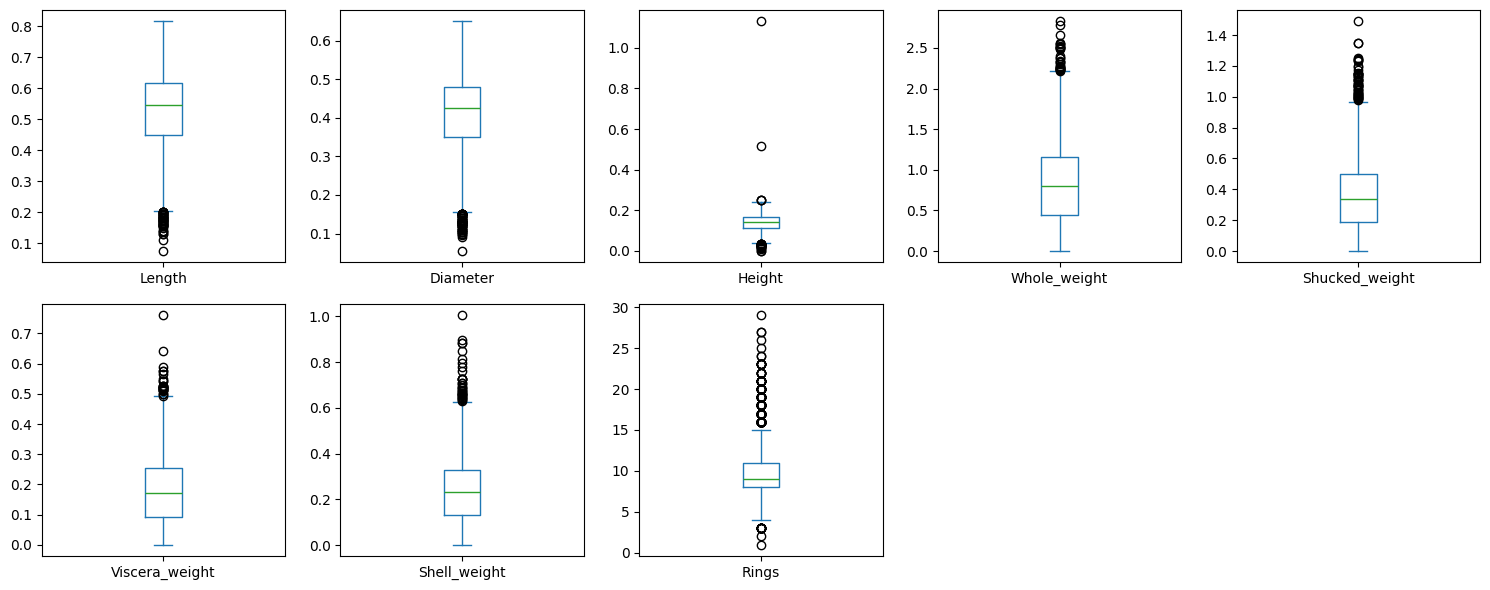


=== 희귀값 개수 ===
Rings
1       1
2       1
3      15
4      57
5     115
6     259
7     391
8     568
9     689
10    634
11    487
12    267
13    203
14    126
15    103
16     67
17     58
18     42
19     32
20     26
21     14
22      6
23      9
24      2
25      1
26      1
27      2
29      1
Name: count, dtype: int64


In [36]:
# 1. EDA
print("=== 결측치 ===")
print(df.isnull().sum())

print("\n=== 이상치 개수 ===")
num_cols = df.drop(columns=["id"]).select_dtypes("number").columns

for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    print(f"{col}: {len(outliers)}개")

# 박스플롯으로 눈으로 확인
df[num_cols].plot(kind="box", subplots=True, layout=(2, 5), figsize=(15, 6))
plt.tight_layout()
plt.show()

print("\n=== 희귀값 개수 ===")
print(df["Rings"].value_counts().sort_index())

In [37]:
# 3. 전처리
## 결측치 : 처리할게 없음
## 이상치 : Height 부분에서 무리에서 뚝 떨어져 혼자 있는 점들이 보여서 Height 부분 지우기
### Length , Diameter 를 이용해서 해당 Height 값이 이상한지 아닌지를 판단
print(df.sort_values("Height", ascending=False).head(3)[["Length", "Diameter", "Height"]])
print(df[df["Height"] == 0][["Length", "Diameter", "Height"]])

df = df[(df["Height"] > 0) & (df["Height"] < 0.4)].reset_index(drop=True)

## 희귀값 : 양 끝의 희귀값들이 하나의 그룹에 포함되도록 lower 와 upper 를 추가
strat = df["Rings"].clip(lower=3, upper=22)

      Length  Diameter  Height
2051   0.455     0.355   1.130
1417   0.705     0.565   0.515
1763   0.775     0.630   0.250
      Length  Diameter  Height
1257   0.430      0.34     0.0
3996   0.315      0.23     0.0


In [38]:
# 4. 입력 / 정답 나누기
X = pd.get_dummies(df.drop(columns=["id", "Rings"]), columns=["Sex"]).values.astype("float32")

## 정답 Rings를 원-핫 인코딩
Y_df = pd.get_dummies(df["Rings"])
labels = Y_df.columns.tolist()
Y = Y_df.values.astype("float32")
print("클래스 순서:", labels, "| Y 모양:", Y.shape)

클래스 순서: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 29] | Y 모양: (4173, 28)


In [39]:
# 3. 학습 / 테스트 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=strat)

In [40]:
# 4. 정규화 (변수마다 범위가 달라서 필요)
#    기준(평균, 표준편차)은 학습 데이터로만 정해야 테스트 정보가 새지 않음
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [47]:
# 5. 모델 구성
#    다중 분류 + 단일 레이블 → 출력층 softmax, 클래스가 3개라 노드 3개
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(Y.shape[1], activation="softmax"),
])


model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,883 (11.26 KB)

 Trainable params: 2,883 (11.26 KB)

 Non-trainable params: 0 (0.00 B)

In [42]:
# 6. 학습
# EarlyStopping 으로 val _loss 를 계속 지켜보다가 지금까지 가장 낮았던 값보다 10 에포크 연속 더 낮아지지 않으면 학습을 멈추고
# 가장 좋았던 시점의 가중치로 되돌린다
# 지금 보다 10번때 에포크에서 val_loss 가 0.8917 로 나오고 그 아래 10개가 모두 이것보다 컸기 때문에 멈추고
# 10번째 에포크 일 때의 가중치로 되돌리고 멈춘다
early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=200, batch_size=32,
    validation_split=0.2, callbacks=[early], verbose=1)

Epoch 1/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.1850 - loss: 2.8664 - val_accuracy: 0.2111 - val_loss: 2.5561
Epoch 2/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2206 - loss: 2.3112 - val_accuracy: 0.2425 - val_loss: 2.3001
Epoch 3/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2603 - loss: 2.1500 - val_accuracy: 0.2380 - val_loss: 2.2066
Epoch 4/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2633 - loss: 2.0845 - val_accuracy: 0.2560 - val_loss: 2.1559
Epoch 5/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2599 - loss: 2.0433 - val_accuracy: 0.2530 - val_loss: 2.1236
Epoch 6/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.2670 - loss: 2.0153 - val_accuracy: 0.2560 - val_loss: 2.1055
Epoch 7/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2779 - loss: 1.9891 - val_accuracy: 0.2740 - val_loss: 2.0761
Epoch 8/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2779 - loss: 1.9668 - val_accuracy: 0.2650 - v

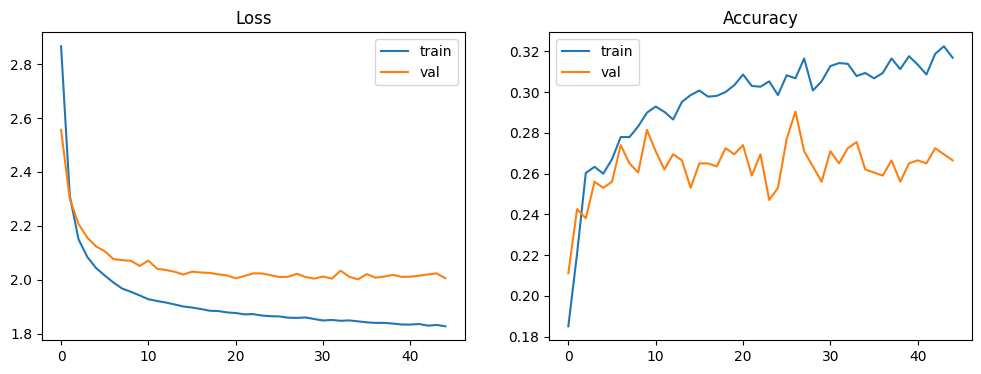

In [43]:
# 6. 학습 곡선 (과적합 여부 확인)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy"); axes[1].legend()
plt.show()

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Accuracy: 0.2502994011976048
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         0
           2       0.00      0.00      0.00         1
           3       0.00      0.00      0.00         2
           4       0.44      0.73      0.55        11
           5       0.29      0.09      0.13        23
           6       0.33      0.46      0.38        52
           7       0.31      0.24      0.27        78
           8       0.30      0.32      0.31       113
           9       0.24      0.37      0.29       138
          10       0.19      0.23      0.20       127
          11       0.27      0.31      0.29        98
          12       0.00      0.00      0.00        54
          13       0.29      0.12      0.17        41
          14       0.12      0.12      0.12        25
          15       0.00      0.00      0.00        21
          16       0.14      0.15      0.15        13
          17 

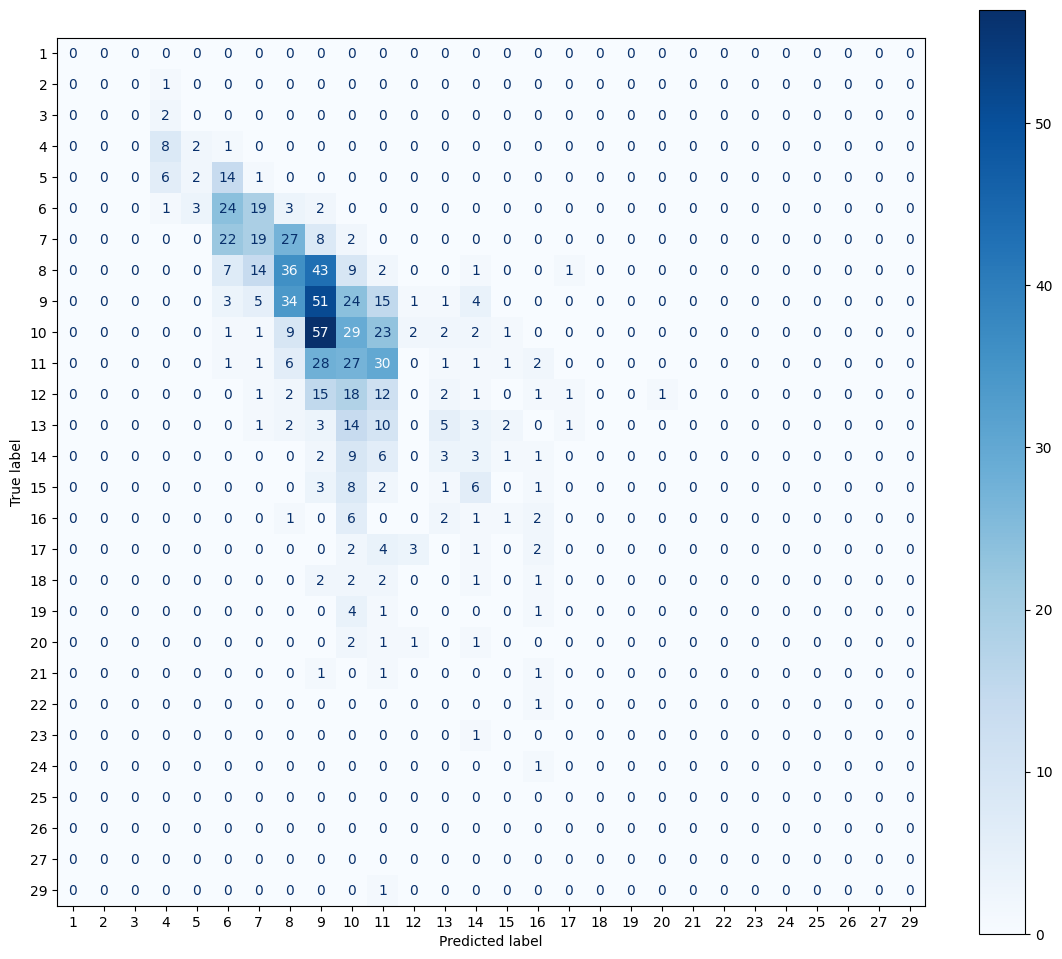

In [44]:
# 7. 평가: 확률 → 클래스 번호, 원-핫 정답 → 클래스 번호
y_pred = np.argmax(model.predict(X_test), axis=1)   # 예측 클래스 번호
y_true = np.argmax(y_test, axis=1)                  # 정답 클래스 번호

all_classes = range(len(labels))
label_names = [str(l) for l in labels]

print("Accuracy:", accuracy_score(y_true, y_pred))
print(classification_report(y_true, y_pred, labels=all_classes,
                            target_names=label_names, zero_division=0))

fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=all_classes),
                       display_labels=label_names).plot(cmap="Blues", ax=ax, values_format="d")
plt.show()

In [ ]:
# 8 . 결과 분석 ( 정확도가 굉장히 낮게 나옴 정확도 : 0.25 가 나옴 )
## 원인 1 : 클래스가 28개나 되고 , 이웃 클래스 간의 특징 구분이 안된다
## 원인 2 : 데이터가 8~11 에 몰려 있다

In [45]:
# 9 . 해결 방법
## Rings 를 몇 개의 그룹으로 묶기
# 예: 어림(1~8) / 성체(9~10) / 노년(11~) 3개 클래스
# 9. 해결 방법: Rings를 3개 나이 그룹으로 묶어서 분류
df["Age_group"] = pd.cut(df["Rings"], bins=[0, 8, 10, 30], labels=["young", "adult", "old"])

# 입력: id, Rings, Age_group 빼고 Sex 원-핫
X = pd.get_dummies(df.drop(columns=["id", "Rings", "Age_group"]), columns=["Sex"]).values.astype("float32")

# 정답: 나이 그룹 원-핫
Y_df = pd.get_dummies(df["Age_group"])
labels = Y_df.columns.tolist()
Y = Y_df.values.astype("float32")
print("클래스 순서:", labels, "| Y 모양:", Y.shape)

# 분할 (나이 그룹 비율 유지)
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=df["Age_group"])

# 스케일링
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

클래스 순서: ['young', 'adult', 'old'] | Y 모양: (4173, 3)


In [48]:
# 10. 재학습
early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=200, batch_size=32,
    validation_split=0.2, callbacks=[early], verbose=1)

Epoch 1/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5749 - loss: 0.8663 - val_accuracy: 0.6168 - val_loss: 0.7956
Epoch 2/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6131 - loss: 0.8036 - val_accuracy: 0.6272 - val_loss: 0.7880
Epoch 3/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6348 - loss: 0.7801 - val_accuracy: 0.6482 - val_loss: 0.7652
Epoch 4/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6423 - loss: 0.7665 - val_accuracy: 0.6377 - val_loss: 0.7573
Epoch 5/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6427 - loss: 0.7544 - val_accuracy: 0.6796 - val_loss: 0.7422
Epoch 6/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6536 - loss: 0.7433 - val_accuracy: 0.6602 - val_loss: 0.7359
Epoch 7/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6562 - loss: 0.7397 - val_accuracy: 0.6512 - val_loss: 0.7474
Epoch 8/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6498 - loss: 0.7342 - val_accuracy: 0.6482 - v

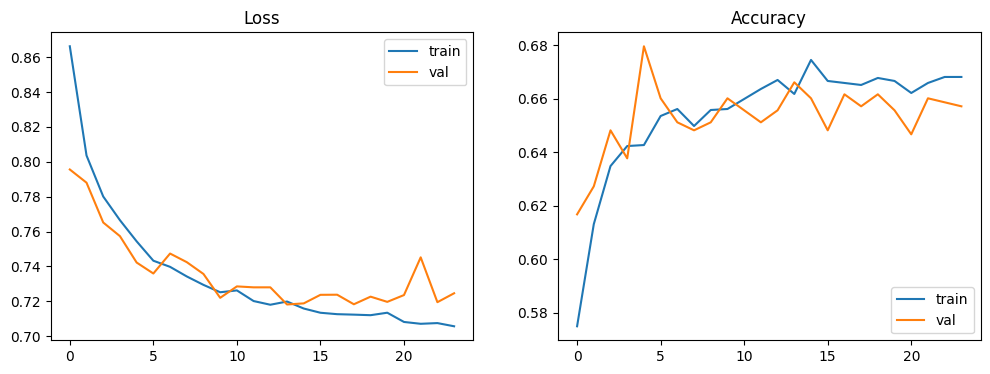

In [49]:
# 11. 학습 곡선 (과적합 여부 확인)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy"); axes[1].legend()
plt.show()

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Accuracy: 0.6850299401197605
              precision    recall  f1-score   support

       young       0.77      0.78      0.78       281
       adult       0.53      0.59      0.56       264
         old       0.77      0.68      0.72       290

    accuracy                           0.69       835
   macro avg       0.69      0.68      0.68       835
weighted avg       0.69      0.69      0.69       835



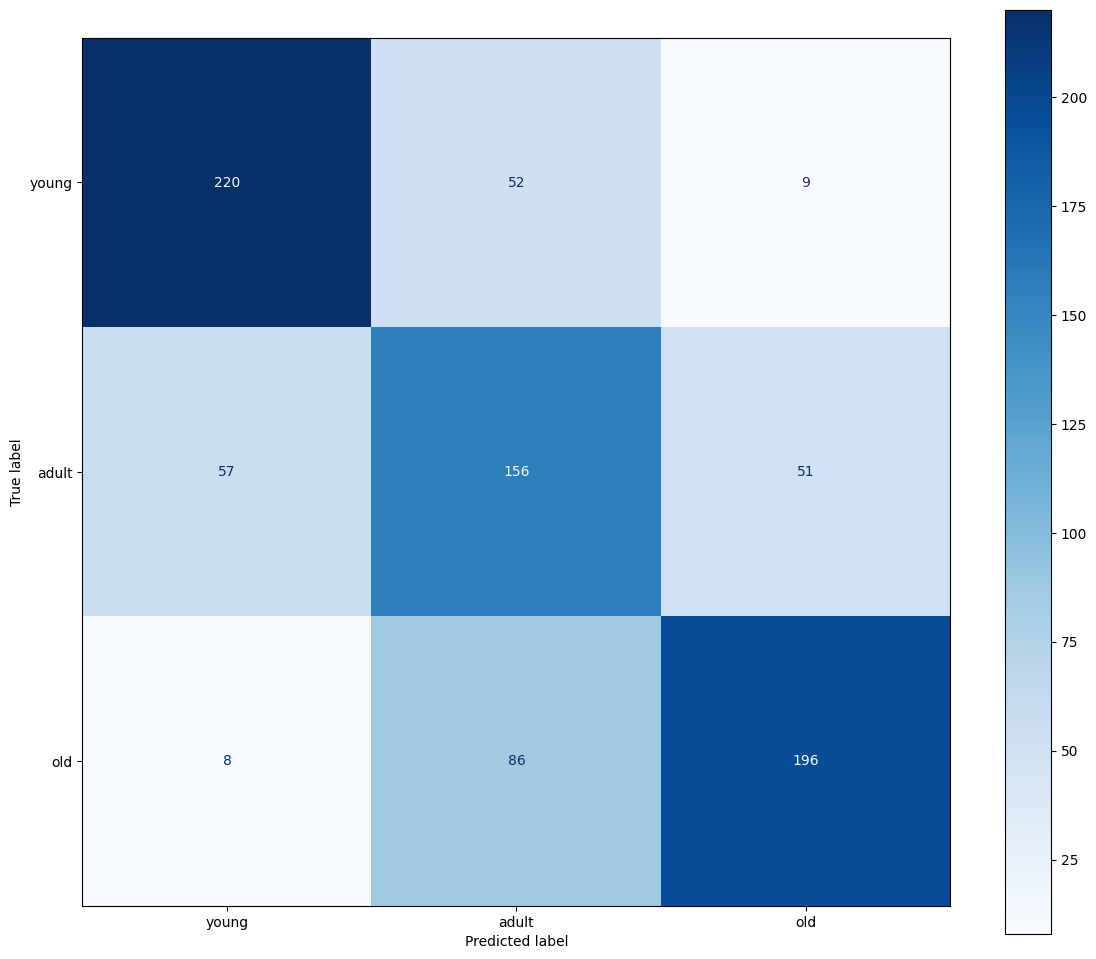

In [50]:
# 12. 재평가: 확률 → 클래스 번호, 원-핫 정답 → 클래스 번호
y_pred = np.argmax(model.predict(X_test), axis=1)   # 예측 클래스 번호
y_true = np.argmax(y_test, axis=1)                  # 정답 클래스 번호

all_classes = range(len(labels))
label_names = [str(l) for l in labels]

print("Accuracy:", accuracy_score(y_true, y_pred))
print(classification_report(y_true, y_pred, labels=all_classes,
                            target_names=label_names, zero_division=0))

fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=all_classes),
                       display_labels=label_names).plot(cmap="Blues", ax=ax, values_format="d")
plt.show()

In [ ]:
# 13 . 결과 재분석
## old 를 adult 로 판단한게 86개로 가장 많다 . 이유는 old 그룹의 경계에 있는 11 , 12 가
## adult의 경계에 있는 10 과 크기 차이가 거의 없어서 제대로 판단하지 못했다